Spectrum of Sodium-22

In [62]:
import matplotlib.pyplot as plt
import numpy as np
from lmfit import models

In [63]:
with open("spectrum_Cs137_231126.csv", "r") as file:
    full_pulseheight = []
    full_counts = []
    i = 0

    for line in file:
        data = line.split(',')

        if i > 0:
            full_pulseheight.append(float(data[0]))
            full_counts.append(float(data[1]))
        else:
            i+=1


In [64]:
pulseheight = []
counts = []
for i in range(len(full_pulseheight)):
    if full_pulseheight[i] > 0:
        pulseheight.append(full_pulseheight[i])
        counts.append(full_counts[i])


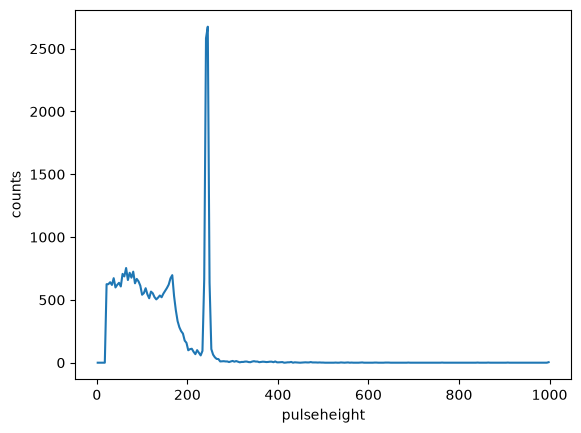

In [65]:
plt.plot(pulseheight, counts)
plt.xlabel("pulseheight")
plt.ylabel("counts")
plt.show()

In [66]:
def lorentzian(x, x0, a, gam ):
  return a * gam**2 / ( gam**2 + ( x - x0 )**2)

def multiple_lorentzian(x, x01, a1, gam1):
    return lorentzian(x, x01, a1, gam1)


In [67]:
spectrum = models.Model(multiple_lorentzian)
fit_result = spectrum.fit(counts, x=pulseheight, x01=250, a1=3000, gam1=25) 

print(fit_result.fit_report())

[[Model]]
    Model(multiple_lorentzian)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 45
    # data points      = 255
    # variables        = 3
    chi-square         = 15256002.6
    reduced chi-square = 60539.6929
    Akaike info crit   = 2810.80111
    Bayesian info crit = 2821.42490
    R-squared          = 0.40408935
[[Variables]]
    x01:   243.175767 +/- 0.15957027 (0.07%) (init = 250)
    a1:    4397.17636 +/- 1074.19278 (24.43%) (init = 3000)
    gam1:  2.39096935 +/- 0.65181702 (27.26%) (init = 25)
[[Correlations]] (unreported correlations are < 0.100)
    C(a1, gam1) = -0.9651


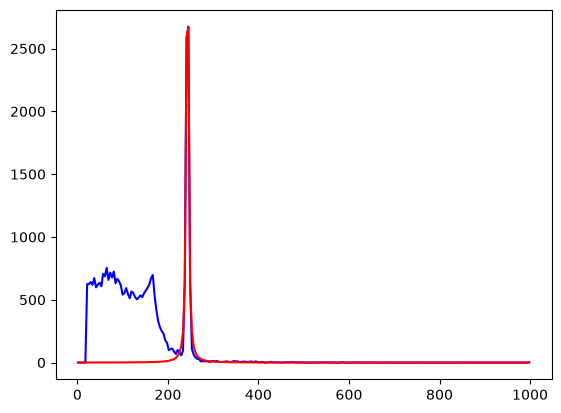

In [68]:
plt.plot(pulseheight, counts, 'b-')
plt.plot(pulseheight, fit_result.best_fit, 'r-')

plt.show()

In [69]:
pulseheight1 = fit_result.params['x01'].value

err_1 = fit_result.params['x01'].stderr

print(pulseheight1, err_1)

243.17576721634862 0.1595702654960676
